<a href="https://colab.research.google.com/github/Shivaji-Vasanth/Deep-Learning/blob/main/Exp24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Task 1: Exact Inference with Variable Elimination

In [22]:

from pgmpy.inference import VariableElimination

queries = {
    'No Evidence': {},
    'Cough + X-ray': {'Cough':1, 'X-ray Result':1},
    'Smoker + Symptoms': {'Smoking':1, 'Cough':1, 'X-ray Result':1},
    'Non-Smoker + Symptoms': {'Smoking':0, 'Cough':1, 'X-ray Result':1}
}

infer = VariableElimination(model)
exact = {}

for name, evidence in queries.items():
    result = infer.query(
        variables=['Lung Disease'],
        evidence=evidence,
        show_progress=False
    )
    exact[name] = float(result.values[1])

print("Exact probabilities:")
for name, value in exact.items():
    print(name, ":", round(value, 4))


Exact probabilities:
No Evidence : 0.1282
Cough + X-ray : 0.9524
Smoker + Symptoms : 0.9846
Non-Smoker + Symptoms : 0.8677


### Task 2: Generate Samples with Forward and Rejection Sampling

In [23]:

sampler = BayesianModelSampling(model)

forward = sampler.forward_sample(size=5000, show_progress=False)

evidence = [
    ('Cough',1),
    ('X-ray Result',1)
]

from pgmpy.factors.discrete import State

rejection = sampler.rejection_sample(
    evidence=[State(k,v) for k,v in evidence],
    size=1000,
    show_progress=False
)

print("Forward samples:")
print(forward.head())

print("\nRejection samples:")
print(rejection.head())


Forward samples:
   Smoking  Lung Disease  Pollution  Cough  X-ray Result  Fatigue
0        1             0          1      0             0        0
1        1             0          0      0             1        1
2        0             0          0      0             0        0
3        1             0          0      0             1        0
4        1             0          0      0             0        0

Rejection samples:
   Smoking  Lung Disease  Pollution  Cough  X-ray Result  Fatigue
0        0             1          1      1             1        1
1        0             1          1      1             1        1
2        1             1          1      1             1        1
3        1             1          0      1             1        1
4        1             1          1      1             1        1


### Task 3: Estimate Queries from the Samples using Pandas

In [24]:

import pandas as pd
import numpy as np

estimates = {}

for name, evidence in queries.items():
    data = forward.copy()

    for col, value in evidence.items():
        data = data[data[col] == value]

    if len(data) > 0:
        estimates[name] = data['Lung Disease'].astype(int).mean()
    else:
        estimates[name] = np.nan

    print(name, ":", round(estimates[name], 4))

print("Rejection estimate:",
      rejection['Lung Disease'].astype(int).mean())


No Evidence : 0.1294
Cough + X-ray : 0.9451
Smoker + Symptoms : 0.9908
Non-Smoker + Symptoms : 0.8125
Rejection estimate: 0.954


### Task 4: Plot Estimated Probability Against Sample Size

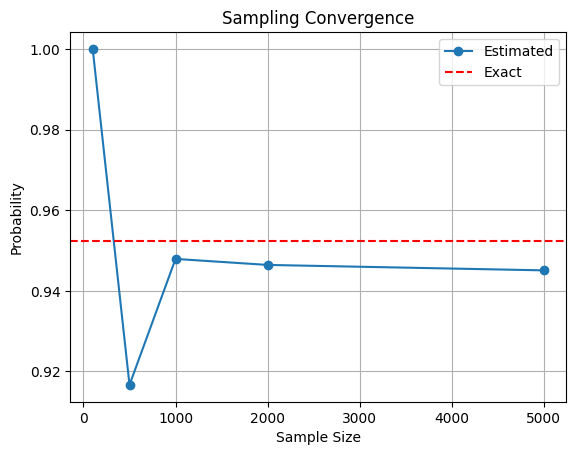

In [25]:

import matplotlib.pyplot as plt

sizes = [100, 500, 1000, 2000, 5000]
values = []

for n in sizes:
    sample = forward.iloc[:n]
    sample = sample[(sample['Cough'] == 1) &
                    (sample['X-ray Result'] == 1)]

    values.append(sample['Lung Disease'].astype(int).mean()
                  if len(sample) else np.nan)

plt.plot(sizes, values, marker='o', label='Estimated')
plt.axhline(exact['Cough + X-ray'], color='red',
            linestyle='--', label='Exact')
plt.xlabel('Sample Size')
plt.ylabel('Probability')
plt.title('Sampling Convergence')
plt.legend()
plt.grid()
plt.show()


### Task 5: Compare Exact and Approximate Answers in a Table

In [26]:

df = pd.DataFrame({
    'Evidence': list(queries.keys()),
    'Exact Probability': list(exact.values()),
    'Approximate Probability': list(estimates.values())
})

df['Absolute Error'] = abs(
    df['Exact Probability'] - df['Approximate Probability']
)

print(df.round(4).to_string(index=False))


             Evidence  Exact Probability  Approximate Probability  Absolute Error
          No Evidence             0.1282                   0.1294          0.0012
        Cough + X-ray             0.9524                   0.9451          0.0073
    Smoker + Symptoms             0.9846                   0.9908          0.0062
Non-Smoker + Symptoms             0.8677                   0.8125          0.0552
